In [1]:
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [3]:
from google.colab import files
uploaded = files.upload()

Saving aotizhongxin_features.csv to aotizhongxin_features.csv


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [5]:
import os
print(os.path.exists("/content/aotizhongxin_features.csv"))

True


In [6]:
import pandas as pd

df = pd.read_csv("/content/aotizhongxin_features.csv")

df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df = df.set_index("datetime")

print("Dataset loaded successfully:", df.shape)
display(df.head())

Dataset loaded successfully: (33876, 51)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,...,wd_NNW,wd_NW,wd_S,wd_SE,wd_SSE,wd_SSW,wd_SW,wd_W,wd_WNW,wd_WSW
datetime,,,,,,,,,,,,,,,,,,,,,
2013-03-02 00:00:00,25,2013,3,2,0,22.0,24.0,24.0,44.0,500.0,...,False,False,False,False,False,False,False,False,False,False
2013-03-02 01:00:00,26,2013,3,2,1,14.0,17.0,21.0,36.0,400.0,...,False,False,False,False,False,False,False,False,False,False
2013-03-02 02:00:00,27,2013,3,2,2,13.0,13.0,20.0,37.0,400.0,...,False,False,False,False,False,False,False,False,False,False
2013-03-02 03:00:00,28,2013,3,2,3,3.0,9.0,13.0,34.0,400.0,...,False,False,False,False,False,False,False,False,False,False
2013-03-02 04:00:00,29,2013,3,2,4,3.0,7.0,18.0,43.0,400.0,...,True,False,False,False,False,False,False,False,False,False


In [7]:
# Split x and y
TARGET = "PM2.5"

X = df.drop(columns=[TARGET]).values
y = df[TARGET].values.reshape(-1, 1)

In [8]:
print("X shape:", X.shape)
print("X type:", type(X))

X shape: (33876, 50)
X type: <class 'numpy.ndarray'>


In [9]:
print(df.columns.tolist())

['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'station', 'PM2.5_next_hour', 'PM2.5_lag_1h', 'PM2.5_lag_3h', 'PM2.5_lag_6h', 'PM2.5_lag_12h', 'PM2.5_lag_24h', 'PM2.5_roll_mean_3h', 'PM2.5_roll_std_3h', 'PM2.5_roll_mean_6h', 'PM2.5_roll_std_6h', 'PM2.5_roll_mean_12h', 'PM2.5_roll_std_12h', 'PM2.5_roll_mean_24h', 'PM2.5_roll_std_24h', 'dayofweek', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'wd_ENE', 'wd_ESE', 'wd_N', 'wd_NE', 'wd_NNE', 'wd_NNW', 'wd_NW', 'wd_S', 'wd_SE', 'wd_SSE', 'wd_SSW', 'wd_SW', 'wd_W', 'wd_WNW', 'wd_WSW']


In [10]:
TARGET = "PM2.5_next_hour"

X = df.drop(columns=[TARGET])
y = df[[TARGET]]

print("LSTM target:", TARGET)
print("X shape:", X.shape)
print("y shape:", y.shape)

LSTM target: PM2.5_next_hour
X shape: (33876, 50)
y shape: (33876, 1)


In [14]:
import numpy as np
from sklearn.preprocessing import StandardScaler

TARGET = "PM2.5_next_hour"

# Recreate X and y
X_df = df.drop(columns=[TARGET]).copy()
y = df[TARGET].to_numpy().reshape(-1, 1)

# Encode station
if "station" in X_df.columns:
    X_df["station"] = X_df["station"].map({"Aotizhongxin": 0})

# Convert Boolean columns to 0 and 1
bool_cols = X_df.select_dtypes(include=["bool"]).columns
X_df[bool_cols] = X_df[bool_cols].astype(int)

# Check remaining non-numeric columns
non_numeric = X_df.select_dtypes(exclude=[np.number]).columns

if len(non_numeric) > 0:
    raise ValueError(f"Non-numeric columns found: {list(non_numeric)}")

# Convert to NumPy
X = X_df.to_numpy(dtype=np.float32)

# Chronological split
n = len(X)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X[:train_end]
X_val = X[train_end:val_end]
X_test = X[val_end:]

y_train = y[:train_end]
y_val = y[train_end:val_end]
y_test = y[val_end:]

# Initialize scalers
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Fit only on training data
X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train)

# Transform validation and test data
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

y_val_scaled = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)

print("Scaling completed successfully!")
print("Training:", X_train_scaled.shape, y_train_scaled.shape)
print("Validation:", X_val_scaled.shape, y_val_scaled.shape)
print("Testing:", X_test_scaled.shape, y_test_scaled.shape)

Scaling completed successfully!
Training: (23713, 50) (23713, 1)
Validation: (5081, 50) (5081, 1)
Testing: (5082, 50) (5082, 1)


In [15]:
import numpy as np

def create_sequences(X, y, seq_len=24):
    Xs, ys = [], []

    for i in range(seq_len, len(X)):
        Xs.append(X[i-seq_len:i])
        ys.append(y[i])

    return np.array(Xs), np.array(ys)

SEQ_LEN = 24

X_train_seq, y_train_seq = create_sequences(
    X_train_scaled, y_train_scaled, SEQ_LEN
)

X_val_seq, y_val_seq = create_sequences(
    X_val_scaled, y_val_scaled, SEQ_LEN
)

X_test_seq, y_test_seq = create_sequences(
    X_test_scaled, y_test_scaled, SEQ_LEN
)

print("Train sequences:", X_train_seq.shape, y_train_seq.shape)
print("Validation sequences:", X_val_seq.shape, y_val_seq.shape)
print("Test sequences:", X_test_seq.shape, y_test_seq.shape)

Train sequences: (23689, 24, 50) (23689, 1)
Validation sequences: (5057, 24, 50) (5057, 1)
Test sequences: (5058, 24, 50) (5058, 1)


In [16]:
import torch

X_train_tensor = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_seq, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_seq, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_seq, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_seq, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_seq, dtype=torch.float32)

print("All LSTM tensors created successfully!")
print("Train:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Test:", X_test_tensor.shape, y_test_tensor.shape)

All LSTM tensors created successfully!
Train: torch.Size([23689, 24, 50]) torch.Size([23689, 1])
Validation: torch.Size([5057, 24, 50]) torch.Size([5057, 1])
Test: torch.Size([5058, 24, 50]) torch.Size([5058, 1])


In [19]:
import torch
import torch.nn as nn

class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, (hidden, cell) = self.lstm(x)
        output = output[:, -1, :]
        output = self.fc(output)
        return output

input_size = X_train_tensor.shape[2]

model = LSTMModel(input_size=input_size)

print(model)

LSTMModel(
  (lstm): LSTM(50, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [20]:
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Device:", device)
print("Loss function: MSELoss")
print("Optimizer: Adam")

Device: cpu
Loss function: MSELoss
Optimizer: Adam


In [21]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

EPOCHS = 30

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    train_loss = running_train_loss / len(train_dataset)
    train_losses.append(train_loss)

    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

    val_loss = running_val_loss / len(val_dataset)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Validation Loss: {val_loss:.6f}"
    )

Epoch [1/30] Train Loss: 0.223145 Validation Loss: 0.151351
Epoch [2/30] Train Loss: 0.140373 Validation Loss: 0.135075
Epoch [3/30] Train Loss: 0.128715 Validation Loss: 0.136064
Epoch [4/30] Train Loss: 0.119915 Validation Loss: 0.136747
Epoch [5/30] Train Loss: 0.113744 Validation Loss: 0.132093
Epoch [6/30] Train Loss: 0.105438 Validation Loss: 0.138625
Epoch [7/30] Train Loss: 0.102426 Validation Loss: 0.131075
Epoch [8/30] Train Loss: 0.095280 Validation Loss: 0.141617
Epoch [9/30] Train Loss: 0.091778 Validation Loss: 0.143134
Epoch [10/30] Train Loss: 0.086527 Validation Loss: 0.137685
Epoch [11/30] Train Loss: 0.082167 Validation Loss: 0.143046
Epoch [12/30] Train Loss: 0.078823 Validation Loss: 0.150002
Epoch [13/30] Train Loss: 0.072020 Validation Loss: 0.163559
Epoch [14/30] Train Loss: 0.067524 Validation Loss: 0.164795
Epoch [15/30] Train Loss: 0.064152 Validation Loss: 0.168148
Epoch [16/30] Train Loss: 0.062760 Validation Loss: 0.166373
Epoch [17/30] Train Loss: 0.05842

In [22]:
import copy
import torch.optim as optim

# Reset model and optimizer
model = LSTMModel(input_size=X_train_tensor.shape[2]).to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 30
PATIENCE = 6

best_val_loss = float("inf")
best_model_state = None
patience_counter = 0

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    train_loss = running_train_loss / len(train_dataset)
    train_losses.append(train_loss)

    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

    val_loss = running_val_loss / len(val_dataset)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Validation Loss: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered!")
        break

model.load_state_dict(best_model_state)

print("Best Validation Loss:", best_val_loss)
print("Best model weights restored successfully!")

Epoch [1/30] Train Loss: 0.212675 Validation Loss: 0.146807
Epoch [2/30] Train Loss: 0.136049 Validation Loss: 0.133420
Epoch [3/30] Train Loss: 0.125389 Validation Loss: 0.134258
Epoch [4/30] Train Loss: 0.118359 Validation Loss: 0.132864
Epoch [5/30] Train Loss: 0.113673 Validation Loss: 0.136955
Epoch [6/30] Train Loss: 0.107442 Validation Loss: 0.136011
Epoch [7/30] Train Loss: 0.104017 Validation Loss: 0.136659
Epoch [8/30] Train Loss: 0.098238 Validation Loss: 0.143035
Epoch [9/30] Train Loss: 0.093156 Validation Loss: 0.144377
Epoch [10/30] Train Loss: 0.088259 Validation Loss: 0.139824
Early stopping triggered!
Best Validation Loss: 0.13286420412395508
Best model weights restored successfully!


In [23]:
model.eval()

with torch.no_grad():
    X_test_device = X_test_tensor.to(device)
    predictions_scaled = model(X_test_device).cpu().numpy()

# Convert predictions and actual values back to original PM2.5 scale
predictions = scaler_y.inverse_transform(predictions_scaled)
actual = scaler_y.inverse_transform(y_test_tensor.numpy())

print("Predictions shape:", predictions.shape)
print("Actual values shape:", actual.shape)
print("First 10 predictions:", predictions[:10].flatten())
print("First 10 actual values:", actual[:10].flatten())

Predictions shape: (5058, 1)
Actual values shape: (5058, 1)
First 10 predictions: [119.36261  148.91077  107.66417   97.320724  82.71815   62.005688
  45.828457  49.680927  56.845272  61.97078 ]
First 10 actual values: [108.  95.  81.  67.  51.  64.  67.  76.  51.  35.]


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))
r2 = r2_score(actual, predictions)

print("LSTM Test Results")
print("-----------------")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

LSTM Test Results
-----------------
MAE: 18.8215
RMSE: 32.6109
R2 Score: 0.8802


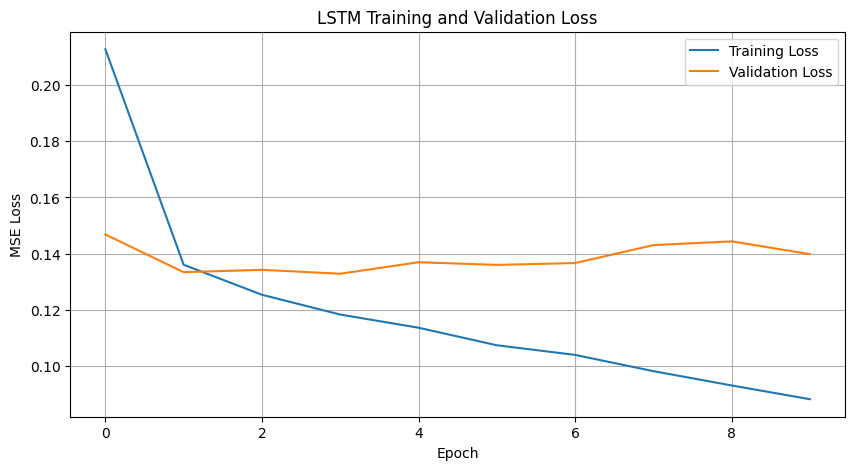

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
import os
import torch
import joblib

os.makedirs("models", exist_ok=True)

# Save model and configuration
torch.save({
    "model_state_dict": model.state_dict(),
    "input_size": X_train_tensor.shape[2],
    "hidden_size": 64,
    "num_layers": 2,
    "seq_len": SEQ_LEN
}, "models/lstm_next_hour.pth")

# Save scalers
joblib.dump(scaler_X, "models/lstm_scaler_X.pkl")
joblib.dump(scaler_y, "models/lstm_scaler_y.pkl")

# Save feature names and order
joblib.dump(X_df.columns.tolist(), "models/lstm_feature_columns.pkl")

print("LSTM model and supporting files saved successfully!")

LSTM model and supporting files saved successfully!


In [27]:
import os

files = [
    "models/lstm_next_hour.pth",
    "models/lstm_scaler_X.pkl",
    "models/lstm_scaler_y.pkl",
    "models/lstm_feature_columns.pkl"
]

for file in files:
    print(file, ":", "Exists" if os.path.exists(file) else "Missing")

models/lstm_next_hour.pth : Exists
models/lstm_scaler_X.pkl : Exists
models/lstm_scaler_y.pkl : Exists
models/lstm_feature_columns.pkl : Exists
